# Background

- **Author**: `馮芳英`
- **Created At**: `2026-11-12`
- **Research Motivation and Context (why are we interested in the findings?)：**
  本 notebook 延續 `youbike_traffic_eda.ipynb` 的資料前處理方式，進一步針對研究範圍站點做幾何、站點層級的探索性分析：站點分布、逐時使用量、範圍內站點間通勤時間、尖峰時刻的站點活動與淨流量、以及路網層級的騎乘熱力圖，作為後續調度與需求模型的視覺化基礎。
  - 分析資料：`data/processed/youbike_traffic/YouBike_traffic_2024_v7.parquet`、`data/processed/youbike_traffic/YouBike_traffic_2025_v7.parquet`（OD 旅次，一列 = 一筆來源交易；借或還任一端在研究範圍內即收錄）。
  - 研究範圍站點：`data/processed/stations_in_field.csv`（113 列、109 個 `StationUID`，含站名與經緯度；4 個站點因位置微調而有新舊兩筆座標，本 notebook 取最新一筆）。
  - 日曆：`data/processed/calendar_2024.csv`、`data/processed/calendar_2025.csv`（組員整理的上班日與臺大學期；2026-11-10 已將學期旗標延伸至開學前 2 天、考完後 7 天）。
  - 樣本：2024-01-01～2025-12-31 全部 18,030,893 筆旅次，未刪除任何列；異常值與疑似重複只計數、不刪除，資料清理方式與 `youbike_traffic_eda.ipynb` 相同。
  - **與舊版（ver3/ver4）的差異**：舊版用即時站點 API（`youbike_immediate.json`）取得車柱容量（`Quantity`），並以手動整理的「可能缺漏站點清單」判斷「臺大校區周邊」範圍，另呼叫新北市 API 補範圍外站點座標。這些即時 API 與手動清單都不是本次指定的三份資料，因此全部移除、改用已核對過的既有資料：
    1. 研究範圍改用 `stations_in_field.csv` 既有的 109 站名單，不再另外手動比對站名。
    2. 第 1 節的「容量地圖」沒有車柱容量可用，改以兩年借還量總和取代，圖名與說明清楚標示這是借還量、不是車柱容量。
    3. 第 6 節路線熱力圖只保留「兩端都在研究範圍內」的旅次（因為只有這些站點有座標），範圍外的往來不納入路線估計；範圍外往來的量，請參考 `youbike_traffic_eda.ipynb` 第 5 節。
    4. 不再使用 Google Colab／Google Drive；圖表直接內嵌在本 notebook 的輸出中，不另外產生 PNG／CSV 檔案。
- **Main Findings and Takeaways：**（將於下方執行後，依實際輸出回填）
- **Future Direction：**
  1. 合併站點剩餘數量 panel，比較本 notebook 的 OD 淨流量與實際車輛數變化，估計調度量。
  2. 路線熱力圖目前僅含研究範圍內互相往來的旅次；之後可視需要另外取得範圍外站點座標，納入跨出範圍的路線。
  3. 比較本 notebook 與 `youbike_traffic_eda.ipynb` 的站點層級結果是否一致，作為資料銜接的交叉核對。


In [2]:
# Colab setup: install packages and a Traditional Chinese font (run once per runtime)
!pip install -q osmnx gdown
!apt-get -qq update > /dev/null && apt-get -qq install -y fonts-noto-cjk > /dev/null
print("Setup done.")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Setup done.


In [4]:
# Load packages here
%matplotlib inline
from pathlib import Path
import hashlib
import io
import math
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.cm import ScalarMappable
from PIL import Image, ImageDraw, ImageEnhance
from IPython.display import display
import osmnx as ox
import networkx as nx

ox.settings.use_cache = False  # do not write an on-disk HTTP cache for this notebook

# Colab: register the Noto CJK fonts installed by the Colab setup cell so matplotlib can find them.
for font_file in Path("/usr/share/fonts").rglob("NotoSansCJK*"):
    font_manager.fontManager.addfont(str(font_file))

# Traditional Chinese font: use the first one available on this machine.
# (Noto's .ttc registers as "Noto Sans CJK JP" in matplotlib, but it contains all TC glyphs.)
CJK_FONTS = ["Noto Sans TC", "Heiti TC", "PingFang TC", "PingFang HK", "Microsoft JhengHei",
             "Noto Sans CJK TC", "Noto Sans CJK JP", "Arial Unicode MS"]
available = {f.name for f in font_manager.fontManager.ttflist}
chosen_font = next((name for name in CJK_FONTS if name in available), None)
if chosen_font is None:
    raise RuntimeError("No Traditional Chinese font found; run the Colab setup cell first.")
plt.rcParams.update({"font.family": chosen_font, "axes.unicode_minus": False, "figure.dpi": 120})
print("Chinese font:", chosen_font)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "AGENTS.md").is_file() and (candidate / "templates").is_dir():
            return candidate
    raise FileNotFoundError("Open this notebook within the student project containing AGENTS.md and templates/.")


if IN_COLAB:
    # Colab has no project folder: build the same data/processed/ layout under /content.
    PROJECT_ROOT = Path("/content/youbike_project")
    (PROJECT_ROOT / "data" / "processed" / "youbike_traffic").mkdir(parents=True, exist_ok=True)
else:
    PROJECT_ROOT = find_project_root()
print("PROJECT_ROOT:", PROJECT_ROOT)


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def fmt_int(x):
    return f"{int(round(x)):,}"


def fmt2(x):
    return f"{x:,.2f}"


def pct(x):
    return f"{100 * x:.2f}%"


# Colours (kept from the previous version of this notebook)
BLUE, ORANGE = "#2a78d6", "#eb6834"
GREEN, RED = "#0ca30c", "#d03b3b"
INK, INK2 = "#0b0b0b", "#52514e"

Chinese font: Noto Sans CJK JP
PROJECT_ROOT: /content/youbike_project


In [ ]:
!gdown 1iKJimpvOKoD-TsKQuWRCuODFmJ1ODRH7
!file "YouBike_traffic_2024_v7.parquet"

!gdown 1wD5vRMeaoMx1BE5w_G1HMfv86KZvB3Yy
!file "YouBike_traffic_2025_v7.parquet"


!gdown 1o5-Owf0iPP4t0D7ijW_N0jiRKaxp1r83
!file "stations_in_field.csv"

!gdown 1Qi5DEu9V_C34QR-FfzoBhxKJD1ihNTnk
!file "calendar_2024.csv"

!gdown 1l3JlJp85MGm5lkf058NqQfWEK53j0wxC
!file "calendar_2025.csv"

!gdown 1A7CHdL2yhMA2OiRXZ5EiI6Tfr2VA0Joe
!file "youbike_flow_hourly_2024.parquet"

!gdown 1bF3doym8nAqAS_1anvR4p4BCqR2YF5Pm
!file "youbike_flow_hourly_2025.parquet"

Downloading...
From: https://drive.google.com/uc?id=1iKJimpvOKoD-TsKQuWRCuODFmJ1ODRH7
To: /content/YouBike_traffic_2024_v7.parquet
100% 44.6M/44.6M [00:00<00:00, 208MB/s]
YouBike_traffic_2024_v7.parquet: Apache Parquet
Downloading...
From: https://drive.google.com/uc?id=1wD5vRMeaoMx1BE5w_G1HMfv86KZvB3Yy
To: /content/YouBike_traffic_2025_v7.parquet
100% 60.5M/60.5M [00:00<00:00, 206MB/s]
YouBike_traffic_2025_v7.parquet: Apache Parquet
Downloading...
From: https://drive.google.com/uc?id=1o5-Owf0iPP4t0D7ijW_N0jiRKaxp1r83
To: /content/stations_in_field.csv
100% 16.7k/16.7k [00:00<00:00, 39.0MB/s]
stations_in_field.csv: CSV Unicode text, UTF-8 text
Downloading...
From: https://drive.google.com/uc?id=1Qi5DEu9V_C34QR-FfzoBhxKJD1ihNTnk
To: /content/calendar_2024.csv
100% 6.93k/6.93k [00:00<00:00, 14.0MB/s]
calendar_2024.csv: CSV Unicode text, UTF-8 text
Downloading...
From: https://drive.google.com/uc?id=1l3JlJp85MGm5lkf058NqQfWEK53j0wxC
To: /content/calendar_2025.csv
100% 6.83k/6.83k [00:00<0

In [8]:
DATA_DIR = Path.cwd()  # !gdown saves the input files into the current folder (/content on Colab)
print("DATA_DIR:", DATA_DIR)

DATA_DIR: /content


In [ ]:
INPUTS = {
    "traffic_2024": ("YouBike_traffic_2024_v7.parquet",
                      "5739637b670bceb34ed2e7271cb78da56f9ea56da310bfb53ce8dccaadd5e119"),
    "traffic_2025": ("YouBike_traffic_2025_v7.parquet",
                      "9b1e3beb9d0e4a164c2ad6662764150768452de126be46329566d6030c0c61d9"),
    "stations_in_field": ("stations_in_field.csv",
                          "fbf0c1797ddbbe59de4852b077ce79dc8243ccc59f08caf4cff0ddfa5eba1ce4"),
    "calendar_2024": ("calendar_2024.csv",
                      "0625623f24d1e21b3f9a9877e486eec6a1703da8891337485e5e52b88335aaee"),
    "calendar_2025": ("calendar_2025.csv",
                      "91a87c16760043bd57b3e15fe85945ce2ebabf8f3b2b9ddca5781a72783553c4"),
    "flow_2024": ("youbike_flow_hourly_2024.parquet",
                  "8739d7f085ee3ea8fb17a91cf223c490bfb28d463c4cf6a2413d62958b9f9ea1"),
    "flow_2025": ("youbike_flow_hourly_2025.parquet",
                  "05b0af6036e4c1dad3b7331fbee69cffd188320b83bc0457a148bd7ca372f4c0"),
}
input_paths = {}
for key, (file_name, expected) in INPUTS.items():
    path = DATA_DIR / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found; run the !gdown cell above first.")
    actual = sha256_file(path)
    if actual != expected:
        raise ValueError(f"{file_name} changed (expected {expected}, got {actual}); "
                         "identify the new version before analysis.")
    input_paths[key] = path
print(f"All {len(INPUTS)} inputs exist and match their expected SHA-256.")

In [ ]:
# --- OD trips (2024 + 2025) ----------------------------------------------------------
TRAFFIC_COLUMNS = ["rent_time", "rent_station", "rent_station_id", "return_time", "return_station",
                   "return_station_id", "rent", "bike_type", "infodate", "trip_group"]
parts = []
for year in (2024, 2025):
    part = pd.read_parquet(input_paths[f"traffic_{year}"])
    assert list(part.columns) == TRAFFIC_COLUMNS, f"{year}: unexpected columns"
    part["source_year"] = year
    parts.append(part)
trips = pd.concat(parts, ignore_index=True)
del parts
RAW_ROWS = len(trips)

for col in ("rent_time", "return_time"):
    assert trips[col].str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:00:00").all(), f"{col} is not hour-precision"
    trips[col] = pd.to_datetime(trips[col], format="%Y-%m-%d %H:%M:%S")
trips["date"] = pd.to_datetime(trips["infodate"], format="%Y-%m-%d")
assert (trips["date"] == trips["rent_time"].dt.normalize()).all(), "infodate differs from the rental date"

OUTSIDE = "-1"  # every row has rent/return station id = -1 for the end that is outside the research scope
rent_in = trips["rent_station_id"] != OUTSIDE
return_in = trips["return_station_id"] != OUTSIDE
assert (rent_in | return_in).all(), "every trip in this file should touch the research scope"

TYPE_ORDER = ["區內旅次", "流出旅次", "流入旅次"]
trips["trip_type"] = pd.Categorical(
    np.select([rent_in & return_in, rent_in & ~return_in], ["區內旅次", "流出旅次"], "流入旅次"),
    categories=TYPE_ORDER)
trips["rent_in_field"] = rent_in.to_numpy()
trips["return_in_field"] = return_in.to_numpy()

PREFIX = "YouBike2.0_"
for col in ("rent_station", "return_station"):
    trips[col] = trips[col].str.removeprefix(PREFIX).astype("category")

rent_dur = trips["rent"]
assert rent_dur.str.fullmatch(r"\d+:[0-5]\d:[0-5]\d").all(), "rent has an unexpected format"
duration_sec = (rent_dur.str[:-6].astype(np.int64) * 3600 + rent_dur.str[-5:-3].astype(np.int64) * 60
                + rent_dur.str[-2:].astype(np.int64))
trips["duration_min"] = duration_sec / 60
trips["rent_hour"] = trips["rent_time"].dt.hour
trips["return_hour"] = trips["return_time"].dt.hour
trips["same_station"] = trips["rent_station"].astype(object) == trips["return_station"].astype(object)
trips["year"] = trips["date"].dt.year
assert (trips["year"] == trips["source_year"]).all()
trips = trips.drop(columns=["rent", "infodate", "bike_type", "trip_group", "source_year"])  # no longer needed; keep memory down

# --- Calendar: used for the exact day count (exposure) and the weekday/holiday split ---
calendar = pd.concat([pd.read_csv(input_paths[f"calendar_{y}"], dtype={"day_off_reason": str}, keep_default_na=False)
                      for y in (2024, 2025)], ignore_index=True)
calendar["date"] = pd.to_datetime(calendar["date"], format="%Y-%m-%d")
assert calendar["date"].is_unique and len(calendar) == 731
assert calendar["date"].min() == pd.Timestamp("2024-01-01") and calendar["date"].max() == pd.Timestamp("2025-12-31")
assert calendar["weekday"].isin([0, 1]).all()
calendar["day_type"] = np.where(calendar["weekday"] == 1, "平日", "假日")
N_DAYS = len(calendar)                                   # 731 calendar days spanning the sample
N_WEEKDAY = int((calendar["weekday"] == 1).sum())
N_HOLIDAY = N_DAYS - N_WEEKDAY

day_type_of = calendar.set_index("date")["day_type"]
trips["day_type"] = pd.Categorical(trips["date"].map(day_type_of), categories=["平日", "假日"])
assert trips["day_type"].notna().all()

# --- Research-scope station roster (coordinates for the map and route sections) -------
stations = pd.read_csv(input_paths["stations_in_field"], dtype={"StationUID": str})
stations = stations.sort_values("last_seen").drop_duplicates("StationUID", keep="last")  # latest position
stations["station_id"] = stations["StationID"].astype(str)
stations["name"] = stations["StationNameZh_tw"].str.removeprefix(PREFIX)
assert stations["station_id"].is_unique and stations["name"].is_unique
STATIONS = stations.set_index("station_id")[["name", "PositionLat", "PositionLon"]].rename(
    columns={"PositionLat": "latitude", "PositionLon": "longitude"})

seen_ids = set(trips.loc[rent_in, "rent_station_id"]) | set(trips.loc[return_in, "return_station_id"])
assert seen_ids <= set(STATIONS.index), "trip data has an in-field station id outside the roster"
missing_ids = sorted(set(STATIONS.index) - seen_ids)
print(f"{len(seen_ids)}/{len(STATIONS)} 個研究範圍站點在旅次資料中有借還紀錄；",
      f"{len(missing_ids)} 個站點完全沒有紀錄" if missing_ids else "全部站點都出現過。")

# Name <-> id consistency check (id is the authoritative key; names are read-only display labels)
name_by_id = (pd.concat([trips.loc[rent_in, ["rent_station_id", "rent_station"]].set_axis(["id", "name"], axis=1),
                         trips.loc[return_in, ["return_station_id", "return_station"]].set_axis(["id", "name"], axis=1)])
              .drop_duplicates())
check = name_by_id.merge(STATIONS["name"], left_on="id", right_index=True, suffixes=("_trip", "_roster"))
mismatch = check[check["name_trip"].astype(str) != check["name_roster"]]
assert mismatch.empty, f"station name disagrees between the trip data and the roster:\n{mismatch}"
print("站點名稱與站點代碼在旅次資料與研究範圍名單之間一致。")

trips = trips.sort_values(["rent_time", "return_time"], kind="stable").reset_index(drop=True)
assert len(trips) == RAW_ROWS, "rows were added or dropped during preparation"
print(f"Analysis sample: {RAW_ROWS:,} trips, {N_DAYS} 個日曆天（{N_WEEKDAY} 平日、{N_HOLIDAY} 假日），"
      f"{len(STATIONS)} 個研究範圍站點")
SHOW = ["rent_time", "rent_station", "return_time", "return_station", "trip_type", "duration_min", "day_type"]
display(trips[SHOW].head(10))


All 5 inputs exist and match their expected SHA-256.
109/109 個研究範圍站點在旅次資料中有借還紀錄； 全部站點都出現過。
站點名稱與站點代碼在旅次資料與研究範圍名單之間一致。
Analysis sample: 18,030,893 trips, 731 個日曆天（491 平日、240 假日），109 個研究範圍站點


,rent_time,rent_station,return_time,return_station,trip_type,duration_min,day_type
0,2024-01-01,芳和國中,2024-01-01,辛亥新生路口東南側,流入旅次,8.100000,假日
1,2024-01-01,芳和國中,2024-01-01,汀州思源街口東南側,流入旅次,25.966667,假日
2,2024-01-01,芳和國中,2024-01-01,汀州思源街口東南側,流入旅次,21.550000,假日
3,2024-01-01,芳和國中,2024-01-01,汀州思源街口東南側,流入旅次,22.033333,假日
4,2024-01-01,捷運大安站(5號出口),2024-01-01,復興南路二段340巷口,流入旅次,12.700000,假日
5,2024-01-01,捷運大安站(5號出口),2024-01-01,辛亥泰順街口,流入旅次,17.150000,假日
6,2024-01-01,捷運大安站(5號出口),2024-01-01,和平復興路口西北側,流入旅次,8.166667,假日
7,2024-01-01,臨江公園,2024-01-01,捷運科技大樓站,流入旅次,13.916667,假日
8,2024-01-01,敦化南路二段81巷,2024-01-01,和平公園東側,流入旅次,10.766667,假日
9,2024-01-01,敦化南路二段81巷,2024-01-01,捷運公館站(3號出口),流入旅次,23.700000,假日


In [10]:
# Summary statistics for every variable used below (N = all trips, 2024-2025 v7).
N = len(trips)
numeric_vars = {"duration_min": "騎乘時長（分鐘，rent 欄換算）", "rent_hour": "借車小時（0–23）",
                "return_hour": "還車小時（0–23）"}
numeric_summary = pd.DataFrame({
    label: {"N（有效）": fmt_int(trips[col].notna().sum()), "缺值 N": fmt_int(trips[col].isna().sum()),
            "平均數": fmt2(trips[col].mean()), "標準差": fmt2(trips[col].std()), "最小值": fmt2(trips[col].min()),
            "P25": fmt2(trips[col].quantile(.25)), "中位數": fmt2(trips[col].median()),
            "P75": fmt2(trips[col].quantile(.75)), "最大值": fmt2(trips[col].max())}
    for col, label in numeric_vars.items()}).T
print(f"表 0-1　數值變數摘要（N = {N:,} 筆旅次）")
display(numeric_summary)

categorical_vars = {"trip_type": "旅次類型", "year": "年度", "day_type": "日別（平日／假日）",
                    "same_station": "同站借還", "rent_station": "借車站（含範圍外）",
                    "return_station": "還車站（含範圍外）"}
rows = []
for col, label in categorical_vars.items():
    counts = trips[col].value_counts(dropna=False)
    nonmissing = int(trips[col].notna().sum())
    for rank, (value, count) in enumerate(counts.head(10).items(), start=1):
        rows.append({"變數": label, "類別數": counts.size, "排名": rank, "類別": value,
                     "筆數": fmt_int(count), "占比（分母 = 非缺值 N）": pct(count / nonmissing),
                     "非缺值 N": fmt_int(nonmissing), "缺值 N": fmt_int(N - nonmissing)})
print("表 0-2　類別變數摘要：前 10 大類別（類別少於 10 時全列；借還站欄位含研究範圍外的站名）")
display(pd.DataFrame(rows).set_index(["變數", "排名"]))


表 0-1　數值變數摘要（N = 18,030,893 筆旅次）


,N（有效）,缺值 N,平均數,標準差,最小值,P25,中位數,P75,最大值
騎乘時長（分鐘，rent 欄換算）,"18,030,893",0,12.65,"1,239.61",0.00,4.65,7.38,13.37,"5,258,885.15"
借車小時（0–23）,"18,030,893",0,14.24,4.65,0.00,11.00,15.00,18.00,23.00
還車小時（0–23）,"18,030,893",0,14.37,4.70,0.00,11.00,15.00,18.00,23.00


表 0-2　類別變數摘要：前 10 大類別（類別少於 10 時全列；借還站欄位含研究範圍外的站名）


類別數           類別          筆數 占比（分母 = 非缺值 N）       非缺值 N 缺值 N
變數        排名                                                               
旅次類型      1      3         區內旅次   9,848,534         54.62%  18,030,893    0
          2      3         流出旅次   4,261,858         23.64%  18,030,893    0
          3      3         流入旅次   3,920,501         21.74%  18,030,893    0
年度        1      2         2025  10,253,912         56.87%  18,030,893    0
          2      2         2024   7,776,981         43.13%  18,030,893    0
日別（平日／假日） 1      2           平日  13,749,556         76.26%  18,030,893    0
          2      2           假日   4,281,337         23.74%  18,030,893    0
同站借還      1      2        False  17,557,518         97.37%  18,030,893    0
          2      2         True     473,375          2.63%  18,030,893    0
借車站（含範圍外） 1   1638  捷運公館站(2號出口)   1,059,785          5.88%  18,030,893    0
          2   1638  捷運公館站(3號出口)     661,328          3.67%  18,030,893    0
          3   1638      捷運科技大樓站     650,484          3.61%  18,030,893    0
          4   1638  臺大第一活動中心西南側     396,275          2.20%  18,030,893    0
          5   1638    臺大新體育館東南側     307,849          1.71%  18,030,893    0
          6   1638      臺大小福樓東側     297,480          1.65%  18,030,893    0
          7   1638       臺大男一舍前     283,023          1.57%  18,030,893    0
          8   1638      臺大社科院西側     252,191          1.40%  18,030,893    0
          9   1638     臺灣科技大學側門     244,140          1.35%  18,030,893    0
          10  1638     臺灣科技大學後門     242,704          1.35%  18,030,893    0
還車站（含範圍外） 1   2699  捷運公館站(2號出口)   1,125,630          6.24%  18,030,893    0
          2   2699  捷運公館站(3號出口)     700,731          3.89%  18,030,893    0
          3   2699      捷運科技大樓站     629,562          3.49%  18,030,893    0
          4   2699  臺大第一活動中心西南側     426,877          2.37%  18,030,893    0
          5   2699      臺大小福樓東側     316,283          1.75%  18,030,893    0
          6   2699    臺大新體育館東南側     314,664          1.75%  18,030,893    0
          7   2699       臺大男一舍前     272,962          1.51%  18,030,893    0
          8   2699     臺灣科技大學後門     259,468          1.44%  18,030,893    0
          9   2699      臺大社科院西側     251,646          1.40%  18,030,893    0
          10  2699     臺大女九舍西南側     246,904          1.37%  18,030,893    0

### The actual analysis starts below

## 1. 研究範圍站點地理分布圖（以兩年借還量取代車柱容量）
**底圖**：OpenStreetMap 的單車圖層（[CyclOSM](https://www.cyclosm.org/)），顯示自行車道、單車路線與停車格。
**範圍與解析度**：依 109 個研究範圍站點的經緯度自動計算（再加邊界留白），可在下方 `ZOOM`、`MAP_DPI` 調整。

圓圈面積與數值成正比，**這裡的數值是 2024–2025 兩年借出 + 還入的總筆數**，不是車柱（可停車位）數量 —— 本次指定的三份資料都沒有車柱容量欄位，因此用「使用量」取代「容量」，請注意兩者意義不同。


In [11]:
# --- Basemap: OpenStreetMap bicycle layer (CyclOSM). Map range and resolution are set here. ---
TILE, SUBDOMAINS = 256, "abc"
TILE_URL = "https://{s}.tile-cyclosm.openstreetmap.fr/cyclosm/{z}/{x}/{y}.png"
ATTRIBUTION = "© OpenStreetMap contributors · CyclOSM"
HEADERS = {"User-Agent": "NTU-YouBike-analysis/2.0 (student data-visualization notebook)"}

LON_PAD, LAT_PAD = 0.004, 0.0015        # margin around the 109 research-scope stations
ZOOM = 17                               # tile zoom: 17 ~= 1.1 m/px at Taipei's latitude
MAP_DPI = 150

MAP_BOUNDS = (STATIONS["longitude"].min() - LON_PAD, STATIONS["latitude"].min() - LAT_PAD,
              STATIONS["longitude"].max() + LON_PAD, STATIONS["latitude"].max() + LAT_PAD)
LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = MAP_BOUNDS


def lon_to_x(lon):                      # global pixel coordinates at ZOOM
    return (np.asarray(lon, dtype=float) + 180.0) / 360.0 * 2 ** ZOOM * TILE


def lat_to_y(lat):
    r = np.radians(np.asarray(lat, dtype=float))
    return (1 - np.log(np.tan(r) + 1 / np.cos(r)) / np.pi) / 2 * 2 ** ZOOM * TILE


X0, Y0 = float(lon_to_x(LON_MIN)), float(lat_to_y(LAT_MAX))
MAP_W = int(round(float(lon_to_x(LON_MAX)) - X0))
MAP_H = int(round(float(lat_to_y(LAT_MIN)) - Y0))


def to_px(lon, lat):
    return lon_to_x(lon) - X0, lat_to_y(lat) - Y0


def fetch_tile(x, y):
    """Fetch one basemap tile into memory -- not cached to disk."""
    url = TILE_URL.format(s=SUBDOMAINS[(x + y) % len(SUBDOMAINS)], z=ZOOM, x=x, y=y)
    for attempt in range(5):
        try:
            r = requests.get(url, headers=HEADERS, timeout=30)
            if r.status_code == 200 and r.headers.get("content-type", "").startswith("image"):
                return Image.open(io.BytesIO(r.content)).convert("RGB")
        except requests.RequestException:
            pass
        time.sleep(2 * (attempt + 1))
    return None


def render_basemap():
    tx0, ty0 = int(X0 // TILE), int(Y0 // TILE)
    tx1, ty1 = int((X0 + MAP_W - 1) // TILE), int((Y0 + MAP_H - 1) // TILE)
    jobs = [(x, y) for y in range(ty0, ty1 + 1) for x in range(tx0, tx1 + 1)]
    print(f"Fetching {len(jobs)} CyclOSM tiles ...")
    with ThreadPoolExecutor(max_workers=4) as ex:
        tiles = list(ex.map(lambda xy: fetch_tile(*xy), jobs))
    canvas = Image.new("RGB", ((tx1 - tx0 + 1) * TILE, (ty1 - ty0 + 1) * TILE), (235, 235, 235))
    for (x, y), t in zip(jobs, tiles):
        if t is not None:
            canvas.paste(t if t.size == (TILE, TILE) else t.resize((TILE, TILE)), ((x - tx0) * TILE, (y - ty0) * TILE))
    n_bad = sum(t is None for t in tiles)
    if n_bad:
        print(f"WARNING: {n_bad} tiles could not be downloaded (shown grey).")
    ox0, oy0 = int(round(X0 - tx0 * TILE)), int(round(Y0 - ty0 * TILE))
    return canvas.crop((ox0, oy0, ox0 + MAP_W, oy0 + MAP_H)).convert("RGBA")


BASEMAP = render_basemap()
m_per_px = 40075016.7 * math.cos(math.radians((LAT_MIN + LAT_MAX) / 2)) / (2 ** ZOOM * TILE)
print(f"Basemap {MAP_W} x {MAP_H} px, CyclOSM zoom {ZOOM} (~{m_per_px:.2f} m/px)")


def radius(v, vmax, rmax=28, rmin=3):
    return rmin + (rmax - rmin) * np.sqrt(abs(v) / vmax) if vmax > 0 else rmin


def hex_rgba(h, alpha):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4)) + (int(alpha * 255),)


def dot(color, label, alpha=1.0):       # legend marker
    return Line2D([], [], marker="o", ls="", ms=9, mfc=color, mec="white", alpha=alpha, label=label)


def draw_circles(df, value_col, vmax, color_fn, alpha=0.65):
    """One circle per station over a copy of the basemap; biggest first so small ones stay visible."""
    img = BASEMAP.copy()
    layer = Image.new("RGBA", img.size, (0, 0, 0, 0))
    d = ImageDraw.Draw(layer)
    for _, r in df.reindex(df[value_col].abs().sort_values(ascending=False).index).iterrows():
        if r[value_col] == 0:
            continue
        x, y = to_px(r["longitude"], r["latitude"])
        rad = radius(r[value_col], vmax)
        d.ellipse([x - rad, y - rad, x + rad, y + rad], fill=hex_rgba(color_fn(r), alpha),
                  outline=(255, 255, 255, 235), width=2)
    return Image.alpha_composite(img, layer)


def map_figure(n_panels=1):
    """One figure, panels stacked vertically, each panel sized to the basemap's pixel aspect ratio."""
    fig, axes = plt.subplots(n_panels, 1, figsize=(MAP_W / MAP_DPI, n_panels * MAP_H / MAP_DPI), squeeze=False)
    fig.subplots_adjust(hspace=0.18, top=0.93)
    return fig, axes[:, 0]


def add_header(fig, text, legend=None):
    fig.suptitle(text, x=0.01, ha="left", fontsize=12.5, color=INK)
    if legend:
        fig.legend(handles=legend, loc="upper right", bbox_to_anchor=(0.99, 1.0), frameon=False, fontsize=9,
                   ncol=len(legend))


def attribution(ax):
    ax.text(MAP_W - 6, MAP_H - 6, ATTRIBUTION, ha="right", va="bottom", fontsize=7, color=INK2,
            bbox=dict(fc=(1, 1, 1, 0.75), ec="none", pad=2))


def show_map(ax, img, df, value_col, title="", n_labels=5, fmt="{:.0f}", vmax=None):
    ax.imshow(img)
    ax.set_axis_off()
    if title:
        ax.set_title(title, loc="left", fontsize=11, color=INK, pad=6)
    vmax = vmax if vmax is not None else df[value_col].abs().max()
    for _, r in df.reindex(df[value_col].abs().sort_values(ascending=False).index).head(n_labels).iterrows():
        x, y = to_px(r["longitude"], r["latitude"])
        rad = radius(r[value_col], vmax)
        ax.annotate(f"{r['name']}  {fmt.format(abs(r[value_col]))}", (x + rad + 4, y), va="center", fontsize=8,
                    color=INK, path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    attribution(ax)


Fetching 88 CyclOSM tiles ...
Basemap 2487 x 1719 px, CyclOSM zoom 17 (~1.08 m/px)


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


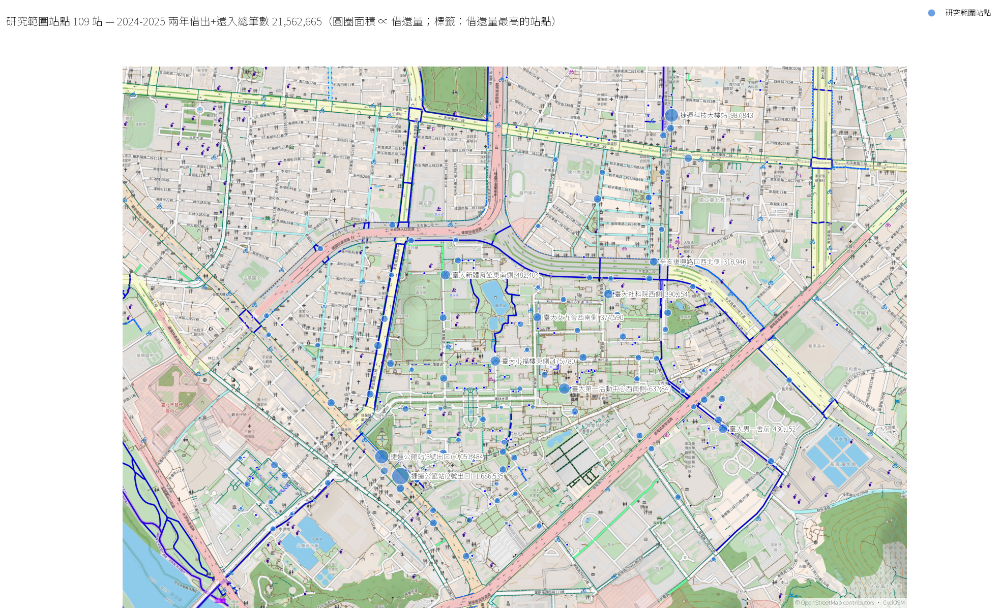

表 1-1　研究範圍站點借還量排行（N = 109 站，2024-2025 合計）


,name,volume
0,捷運公館站(2號出口),1686535
1,捷運公館站(3號出口),1051484
2,捷運科技大樓站,987843
3,臺大第一活動中心西南側,637841
4,臺大新體育館東南側,482404
5,臺大小福樓東側,475780
6,臺大男一舍前,430152
7,臺大社科院西側,390154
8,臺大女九舍西南側,374590
9,辛亥復興路口西北側,318946


In [ ]:
volume = (trips.loc[rent_in, "rent_station_id"].value_counts()
          .add(trips.loc[return_in, "return_station_id"].value_counts(), fill_value=0))
map_df = STATIONS.join(volume.rename("volume")).fillna({"volume": 0.0})
vmax1 = map_df["volume"].max()

img = draw_circles(map_df, "volume", vmax1, lambda r: BLUE)
fig, (ax,) = map_figure(1)
show_map(ax, img, map_df, "volume", n_labels=10, fmt="{:,.0f}")
add_header(fig, f"研究範圍站點 {len(map_df)} 站 — 2024-2025 兩年借出+還入總筆數 {map_df['volume'].sum():,.0f}"
                "（圓圈面積 ∝ 借還量；標籤：借還量最高的站點）", [dot(BLUE, "研究範圍站點", .7)])
plt.show()

print(f"表 1-1　研究範圍站點借還量排行（N = {len(map_df)} 站，2024-2025 合計）")
map_df[["name", "volume"]].sort_values("volume", ascending=False).reset_index(drop=True).head(15)


## 2. 每小時使用量：借車與在途（平日 vs. 假日）
- **借車（borrowed）**：平均每日在該小時「開始」借出的旅次數，起點在研究範圍內。
- **在途（in use）**：平均每日在該小時仍在騎乘中的旅次數（從借車小時到還車小時都算在內），只要旅次有一端在研究範圍內就算。

平日與假日分開計算，各自除以平日／假日的實際天數（491 / 240 天），避免天數不同造成偏誤；方法與 `youbike_traffic_eda.ipynb` 第 3.1 節相同。


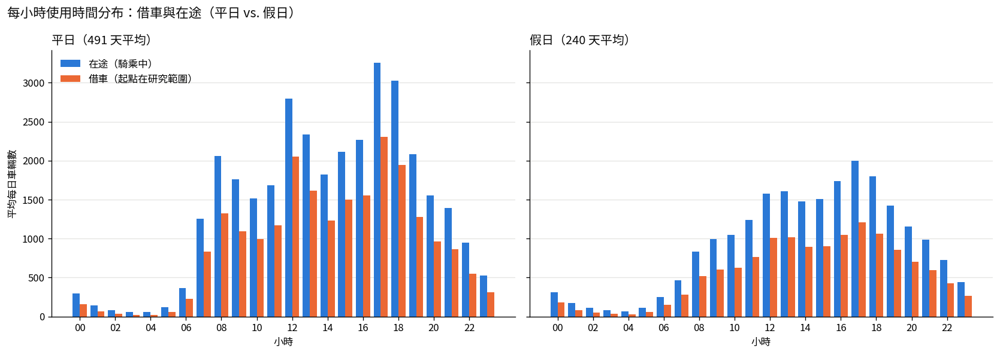

表 2-1　每小時平均借車／在途車輛數（平日、假日分開計算）


,hour,平日_借車,平日_在途,假日_借車,假日_在途
0,0,162.1,292.9,179.7,309.5
1,1,67.6,140.1,83.1,172.6
2,2,38.5,85.3,51.9,110.2
3,3,23.2,59.4,34.2,78.2
4,4,21.7,56.9,29.3,67.7
5,5,58.0,119.4,58.0,112.9
6,6,226.9,365.5,151.0,251.2
7,7,834.3,1255.7,284.4,466.9
8,8,1322.2,2062.8,521.5,832.7
9,9,1096.1,1757.9,603.5,996.3


In [12]:
def hourly_borrowed_in_use(sub, day_count):
    borrowed = np.bincount(sub.loc[sub["rent_in_field"], "rent_hour"], minlength=24) / day_count
    start = sub["rent_time"].dt.floor("h")
    span = ((sub["return_time"].dt.floor("h") - start) / pd.Timedelta(hours=1)).astype(int) + 1
    span_v = span.to_numpy()
    offsets = np.arange(span_v.sum()) - np.repeat(np.cumsum(span_v) - span_v, span_v)
    hours_in_use = (np.repeat(start.dt.hour.to_numpy(), span_v) + offsets) % 24
    in_use = np.bincount(hours_in_use, minlength=24) / day_count
    return borrowed, in_use

hourly = {}
for label, day_count in [("平日", N_WEEKDAY), ("假日", N_HOLIDAY)]:
    b, u = hourly_borrowed_in_use(trips[trips["day_type"] == label], day_count)
    hourly[label] = pd.DataFrame({"hour": range(24), "借車": b, "在途": u})

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, label in zip(axes, ["平日", "假日"]):
    h = hourly[label]
    x = np.arange(24)
    w = 0.4
    ax.bar(x - w / 2, h["在途"], w, color=BLUE, label="在途（騎乘中）")
    ax.bar(x + w / 2, h["借車"], w, color=ORANGE, label="借車（起點在研究範圍）")
    ax.set_xticks(x[::2], [f"{hh:02d}" for hh in x[::2]])
    ax.set_xlabel("小時")
    n_days_label = N_WEEKDAY if label == "平日" else N_HOLIDAY
    ax.set_title(f"{label}（{n_days_label} 天平均）", loc="left", fontsize=12, color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
axes[0].set_ylabel("平均每日車輛數")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("每小時使用時間分布：借車與在途（平日 vs. 假日）", x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.show()

hourly_table = hourly["平日"][["hour"]].copy()
for label in ["平日", "假日"]:
    hourly_table[f"{label}_借車"] = hourly[label]["借車"].round(1)
    hourly_table[f"{label}_在途"] = hourly[label]["在途"].round(1)
print("表 2-1　每小時平均借車／在途車輛數（平日、假日分開計算）")
hourly_table


## 3. 研究範圍內站點間的平均通勤時間
只看兩端都在研究範圍內、且起訖站不同的旅次（區內旅次中排除同站借還）。用四分位距（IQR）法在**每一對起訖站內**各自篩掉離群值（保留 Q1 − 1.5·IQR 到 Q3 + 1.5·IQR），對應中途停留、繞路等不屬於單純通勤的旅次，只列出清理後至少有 `MIN_TRIPS` 筆旅次的站對。


In [13]:
MIN_TRIPS = 20

campus = trips[(trips["trip_type"] == "區內旅次") & ~trips["same_station"]].copy()

# Per-pair Q1/Q3 computed on the ~11k distinct pairs, then merged back (cheaper than .transform on 9M rows)
pair_q = (campus.groupby(["rent_station", "return_station"], observed=True)["duration_min"]
          .quantile([0.25, 0.75]).unstack())
pair_q.columns = ["q1", "q3"]
campus = campus.merge(pair_q, on=["rent_station", "return_station"], how="left")
iqr = campus["q3"] - campus["q1"]
clean = campus[(campus["duration_min"] >= campus["q1"] - 1.5 * iqr) & (campus["duration_min"] <= campus["q3"] + 1.5 * iqr)]
print(f"{len(campus):,} 筆研究範圍內站對旅次；清理後移除 {len(campus) - len(clean):,} 筆離群值"
      f"（{(len(campus) - len(clean)) / max(len(campus), 1):.1%}）")


def mmss(mins):
    s = int(round(mins * 60))
    return f"{s // 60}:{s % 60:02d}"


commute = (clean.groupby(["rent_station", "return_station"], observed=True)["duration_min"]
           .agg(trips="size", avg_min="mean", median_min="median").reset_index())
commute = commute[commute["trips"] >= MIN_TRIPS].sort_values("trips", ascending=False)
commute["平均通勤時間"] = commute["avg_min"].map(mmss)
commute["中位數"] = commute["median_min"].map(mmss)

commute_table = commute.rename(columns={"rent_station": "租借站", "return_station": "歸還站", "trips": "旅次數"})[
    ["租借站", "歸還站", "平均通勤時間", "中位數", "旅次數"]].reset_index(drop=True)
print(f"表 3-1　研究範圍內站對平均通勤時間（N = {len(clean):,} 筆清理後旅次，{len(commute_table):,} 個站對 >= {MIN_TRIPS} 筆；前 30 名）")
display(commute_table.head(30))


9,375,159 筆研究範圍內站對旅次；清理後移除 1,030,471 筆離群值（11.0%）
表 3-1　研究範圍內站對平均通勤時間（N = 8,344,688 筆清理後旅次，11,379 個站對 >= 20 筆；前 30 名）


,租借站,歸還站,平均通勤時間,中位數,旅次數
0,臺大男一舍前,捷運公館站(2號出口),6:47,6:37,46515
1,臺大第一活動中心西南側,捷運公館站(3號出口),4:24,4:14,43761
2,捷運公館站(2號出口),臺大男一舍前,7:14,7:04,35853
3,捷運公館站(3號出口),臺大第一活動中心西南側,4:13,4:05,33909
4,敦親公園,捷運科技大樓站,4:03,3:55,30798
5,捷運科技大樓站,敦親公園,4:37,4:23,30286
6,臺大新體育館東南側,捷運公館站(3號出口),4:46,4:33,27541
7,捷運公館站(2號出口),臺大第一活動中心西南側,4:33,4:24,27195
8,臺大男八舍東側,捷運公館站(2號出口),6:53,6:43,25306
9,臺大女九舍西南側,捷運公館站(3號出口),5:15,5:03,24666


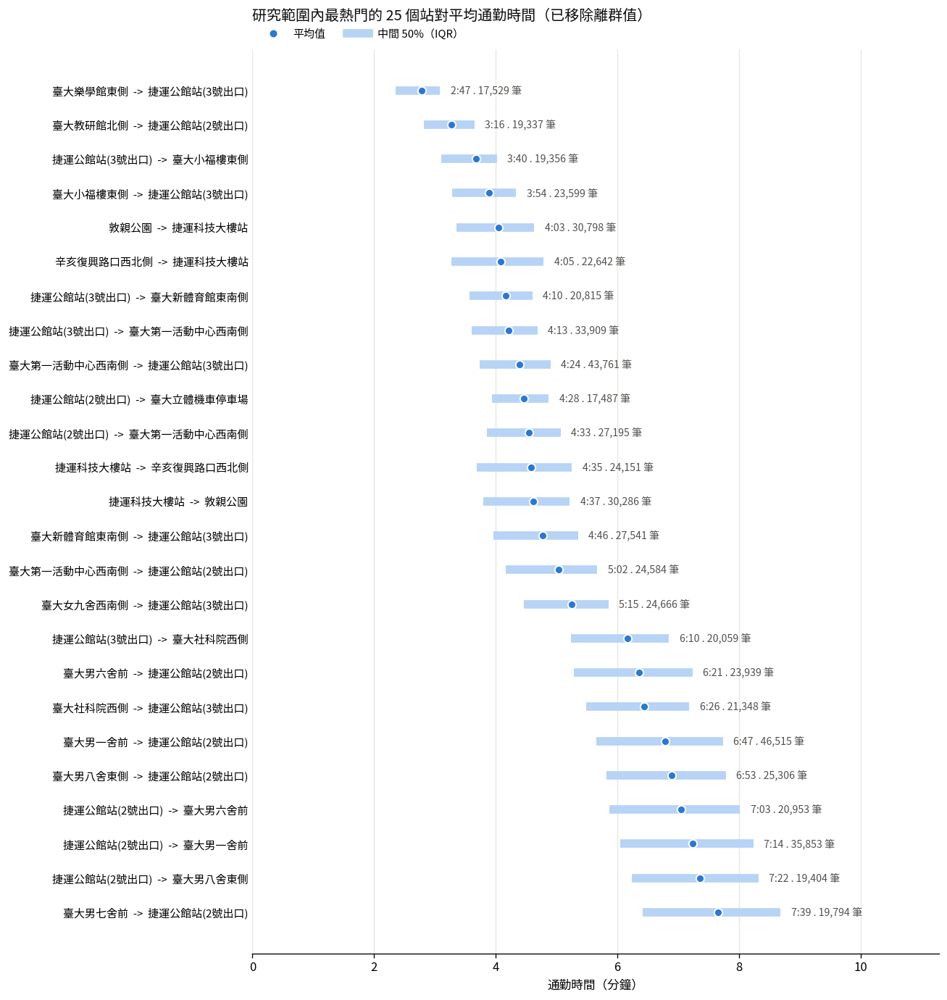

In [14]:
# Chart: average commute time for the busiest in-field station pairs
TOP_N = 25

pair_stats = (clean.groupby(["rent_station", "return_station"], observed=True)["duration_min"]
              .agg(trips="size", avg="mean", q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
              .reset_index())
pair_stats = (pair_stats[pair_stats["trips"] >= MIN_TRIPS]
              .nlargest(TOP_N, "trips").sort_values("avg").reset_index(drop=True))
pair_stats["label"] = pair_stats["rent_station"].astype(str) + "  ->  " + pair_stats["return_station"].astype(str)

fig, ax = plt.subplots(figsize=(11, 0.4 * len(pair_stats) + 1.6))
y = np.arange(len(pair_stats))
ax.hlines(y, pair_stats["q1"], pair_stats["q3"], color="#b7d3f6", linewidth=7, zorder=2)
ax.scatter(pair_stats["avg"], y, s=45, color=BLUE, edgecolor="white", linewidth=1.2, zorder=3)
xmax = pair_stats["q3"].max()
for i, r in pair_stats.iterrows():
    ax.text(r["q3"] + xmax * 0.02, i, f"{mmss(r['avg'])} . {r['trips']:,} 筆", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, pair_stats["label"], fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, xmax * 1.3)
ax.set_xlabel("通勤時間（分鐘）")
ax.set_title(f"研究範圍內最熱門的 {len(pair_stats)} 個站對平均通勤時間（已移除離群值）", loc="left", fontsize=12, color=INK, pad=24)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], marker="o", ls="", ms=7, mfc=BLUE, mec="white", label="平均值"),
                   Line2D([], [], color="#b7d3f6", lw=7, label="中間 50%（IQR）")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()


## 4、5. 尖峰時刻（09、12、16 點）的站點活動與淨流量
對每個研究範圍站點與每個小時，計算 731 天的平均：
- **總活動量** = 借出 + 還入
- **淨流量** = 還入 − 借出：🟢 綠色代表還入多於借出（車輛流入，需要空位）；🔴 紅色代表借出多於還入（車輛流出，提供車源）。

三個時刻使用同一個圓圈比例，方便互相比較。


In [15]:
HOURS = [9, 12, 16]

rent_h = (trips[trips["rent_in_field"]].groupby(["rent_station_id", "rent_hour"]).size()
          .rename_axis(["station_id", "hour"]))
ret_h = (trips[trips["return_in_field"]].groupby(["return_station_id", "return_hour"]).size()
         .rename_axis(["station_id", "hour"]))
flow = pd.concat({"rentals": rent_h, "returns": ret_h}, axis=1).fillna(0) / N_DAYS
flow["activity"] = flow["rentals"] + flow["returns"]
flow["net"] = flow["returns"] - flow["rentals"]

idx = pd.MultiIndex.from_product([STATIONS.index, range(24)], names=["station_id", "hour"])
flow = flow.reindex(idx, fill_value=0).reset_index().merge(STATIONS.reset_index(), on="station_id")
flow_sel = flow[flow["hour"].isin(HOURS)]


def three_panel(images, value_col, suptitle, legend, fmt, n_labels=5):
    fig, axes = map_figure(len(images))
    vmax = flow_sel[value_col].abs().max()
    for ax, h, img in zip(axes, HOURS, images):
        show_map(ax, img, flow_sel[flow_sel["hour"] == h], value_col, f"{h:02d}:00", n_labels=n_labels, fmt=fmt, vmax=vmax)
    add_header(fig, suptitle, legend)
    plt.show()


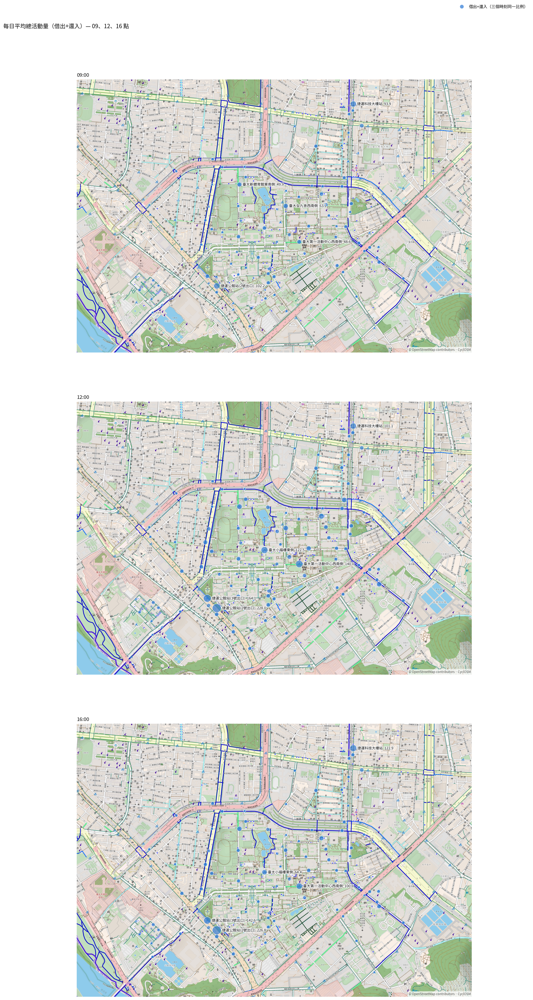

表 4-1　09 點活動量前 10 名研究範圍站點


hour,9,12,16
name,,,
捷運公館站(2號出口),102.2,228.0,226.8
捷運科技大樓站,93.9,101.1,122.9
臺大女九舍西南側,63.1,72.1,38.9
臺大新體育館東南側,49.9,74.3,62.9
臺大第一活動中心西南側,48.6,140.0,100.6
捷運科技大樓站(台北教育大學),42.4,36.2,37.8
捷運公館站(3號出口),41.0,164.1,142.6
臺大小福樓東側,38.5,122.5,64.4
臺大樂學館東側,38.3,45.2,29.9


In [16]:
# 4. Activity map
amax = flow_sel["activity"].max()
activity_imgs = [draw_circles(flow_sel[flow_sel["hour"] == h], "activity", amax, lambda r: BLUE) for h in HOURS]
three_panel(activity_imgs, "activity", "每日平均總活動量（借出+還入）— 09、12、16 點",
            [dot(BLUE, "借出+還入（三個時刻同一比例）", .7)], "{:.1f}")

print("表 4-1　09 點活動量前 10 名研究範圍站點")
(flow_sel.pivot_table(index="name", columns="hour", values="activity").round(1)
 .sort_values(HOURS[0], ascending=False).head(10))


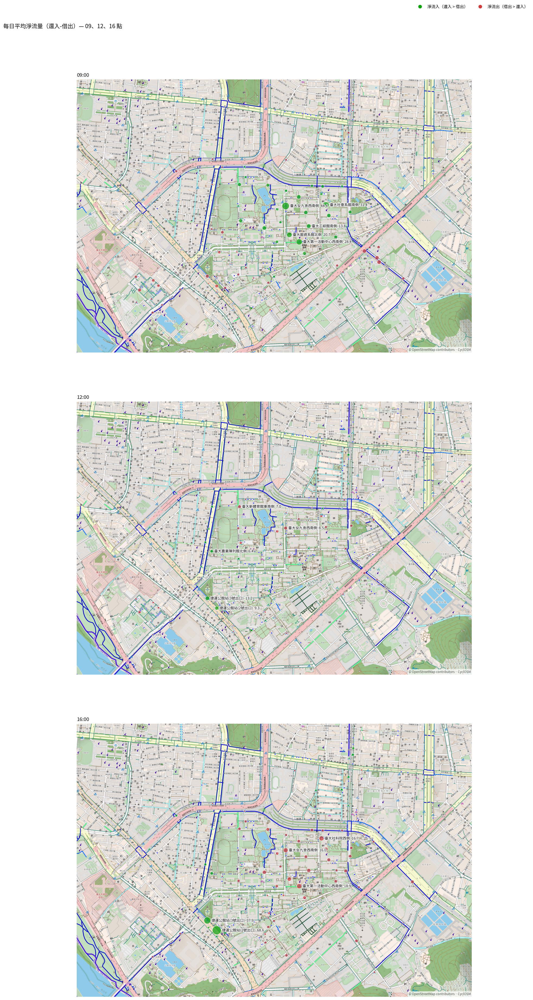

表 5-1　09 點淨流量排序（研究範圍站點）


hour,9,12,16
name,,,
臺大女九舍西南側,44.4,-8.5,-16.0
臺大社會系館南側,31.4,-3.3,-10.4
臺大第一活動中心西南側,28.4,0.0,-18.9
臺大圖資系館北側,20.7,-3.8,-10.6
臺大工綜館南側,13.8,1.3,-9.8
...,...,...,...
捷運公館站(3號出口),-8.1,13.2,37.9
臺大卓越研究大樓,-8.5,-4.7,-2.1
臺大男六舍前,-11.3,-1.9,-0.5


In [17]:
# 5. Net flow map
nmax = flow_sel["net"].abs().max()
net_imgs = [draw_circles(flow_sel[flow_sel["hour"] == h], "net", nmax,
                         lambda r: GREEN if r["net"] > 0 else RED, alpha=0.7) for h in HOURS]
three_panel(net_imgs, "net", "每日平均淨流量（還入-借出）— 09、12、16 點",
            [dot(GREEN, "淨流入（還入 > 借出）"), dot(RED, "淨流出（借出 > 還入）")], "{:.1f}")

print("表 5-1　09 點淨流量排序（研究範圍站點）")
flow_sel.pivot_table(index="name", columns="hour", values="net").round(1).sort_values(HOURS[0], ascending=False)


## 6. 路線熱力圖 — 09、11、16 點（僅研究範圍內互相往來的旅次）
交易資料只有借車站與還車站、沒有實際 GPS 軌跡，因此用 OpenStreetMap 單車路網（OSMnx，`network_type='bike'`，雙向皆可通行）找每筆旅次的最短路徑，再把每個路段「平均每日經過的旅次數」加總。

- 只包含**兩端都在研究範圍內**的旅次（trip_type = 區內旅次，且排除同站借還）：範圍外站點沒有座標，無法估計路線；範圍外往來請見 `youbike_traffic_eda.ipynb` 第 5 節。
- 顏色（淺→深橙）與線寬在三個時刻使用同一個 log 尺度，方便互相比較。
- 這是「假設騎最短路徑」的估計值，實際騎乘路線可能不同。


In [18]:
# 6a. Route every in-field-to-in-field trip on the OSM bike network
HEAT_HOURS = [9, 11, 16]
GRAPH_PAD = 0.006
GW, GS, GE, GN = LON_MIN - GRAPH_PAD, LAT_MIN - GRAPH_PAD, LON_MAX + GRAPH_PAD, LAT_MAX + GRAPH_PAD

od = trips[trips["rent_hour"].isin(HEAT_HOURS) & (trips["trip_type"] == "區內旅次") & ~trips["same_station"]]
od = (od.groupby(["rent_hour", "rent_station_id", "return_station_id"]).size() / N_DAYS).rename("per_day").reset_index()
print(f"{od['per_day'].sum():,.1f} 筆/日（三個時刻合計，僅區內旅次）用於路線估計")

print("下載 OSM 單車路網 ...")
G = ox.graph_from_bbox(bbox=(GW, GS, GE, GN), network_type="bike")
Gu = ox.convert.to_undirected(G)
print(f"{Gu.number_of_nodes():,} 個節點、{Gu.number_of_edges():,} 條邊")

node_of = dict(zip(STATIONS.index,
                   ox.distance.nearest_nodes(Gu, X=STATIONS["longitude"].values, Y=STATIONS["latitude"].values)))
od["src"] = od["rent_station_id"].map(node_of)
od["dst"] = od["return_station_id"].map(node_of)

t0 = time.time()
paths = {}
for src, grp in od.groupby("src"):
    _, p = nx.single_source_dijkstra(Gu, src, weight="length")
    for dst in set(grp["dst"]):
        if dst in p:
            paths[(src, dst)] = p[dst]
print(f"{len(paths):,} 條路線，共花 {time.time() - t0:.0f} 秒")

seg_flow = {h: {} for h in HEAT_HOURS}
for h, src, dst, v in od[["rent_hour", "src", "dst", "per_day"]].itertuples(index=False):
    p = paths.get((src, dst))
    if not p or len(p) < 2:
        continue
    f = seg_flow[h]
    for u, w in zip(p[:-1], p[1:]):
        key = (u, w) if u < w else (w, u)
        f[key] = f.get(key, 0.0) + v


def edge_data(key):
    return min(Gu.get_edge_data(*key).values(), key=lambda d: d.get("length", 0))


_geom = {}


def edge_px(key):
    if key not in _geom:
        d = edge_data(key)
        if "geometry" in d:
            lon, lat = np.asarray(d["geometry"].xy)
        else:
            u, v = key
            lon = [Gu.nodes[u]["x"], Gu.nodes[v]["x"]]
            lat = [Gu.nodes[u]["y"], Gu.nodes[v]["y"]]
        _geom[key] = np.column_stack(to_px(lon, lat))
    return _geom[key]


def street_name(key):
    n = edge_data(key).get("name", "")
    return "/".join(n) if isinstance(n, list) else (n if isinstance(n, str) else "")


2,349.4 筆/日（三個時刻合計，僅區內旅次）用於路線估計
下載 OSM 單車路網 ...
4,348 個節點、6,171 條邊
10,826 條路線，共花 4 秒


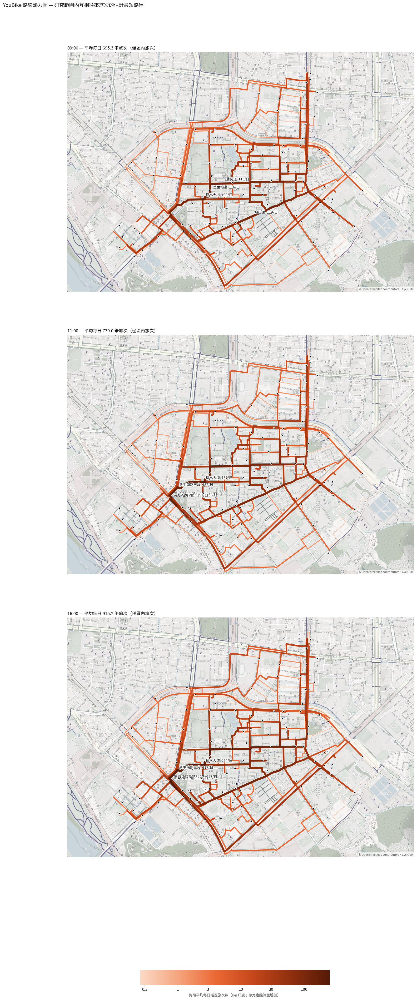

In [19]:
# 6b. Route heatmap: one shared colour/width scale for the three hours
HEAT_CMAP = LinearSegmentedColormap.from_list(
    "heat_orange", ["#fbd9c6", "#f5a47d", "#eb6834", "#c4461a", "#8f2f0e", "#561a06"])
all_vals = np.concatenate([np.fromiter(f.values(), float) for f in seg_flow.values() if f])
HEAT_VMAX = all_vals.max()
HEAT_VMIN = max(np.percentile(all_vals, 5), HEAT_VMAX / 1000)
heat_norm = LogNorm(vmin=HEAT_VMIN, vmax=HEAT_VMAX, clip=True)

_g = ImageEnhance.Color(BASEMAP.convert("RGB")).enhance(0.3)
HEAT_BASE = Image.blend(_g, Image.new("RGB", _g.size, "white"), 0.35)


def lw_px(v):
    return 1.0 + 5.0 * np.asarray(heat_norm(v))


def heat_panel(ax, h, n_labels=4):
    f = seg_flow[h]
    keys = sorted(f, key=f.get)
    segs = [edge_px(k) for k in keys]
    vals = np.array([f[k] for k in keys])
    ax.imshow(HEAT_BASE)
    ax.set_axis_off()
    lws = lw_px(vals)
    ax.add_collection(LineCollection(segs, colors="white", linewidths=lws + 1.5, capstyle="round",
                                     joinstyle="round", alpha=0.9))
    ax.add_collection(LineCollection(segs, cmap=HEAT_CMAP, norm=heat_norm, array=vals, linewidths=lws,
                                     capstyle="round", joinstyle="round"))
    ax.set_xlim(0, MAP_W)
    ax.set_ylim(MAP_H, 0)
    sx, sy = to_px(STATIONS["longitude"].values, STATIONS["latitude"].values)
    ax.scatter(sx, sy, s=18, c=INK, edgecolors="white", linewidths=1.0, zorder=5)
    best = {}
    for k in reversed(keys):
        nm = street_name(k)
        if nm and nm not in best:
            best[nm] = k
        if len(best) >= n_labels:
            break
    for nm, k in best.items():
        xy = edge_px(k)
        x, y = xy[len(xy) // 2]
        if 0 <= x <= MAP_W and 0 <= y <= MAP_H:
            label = f"{nm}  {f[k]:.1f}/日" if f[k] < 10 else f"{nm}  {f[k]:.0f}/日"
            ax.annotate(label, (x, y), xytext=(8, 8), textcoords="offset points", fontsize=9, color=INK,
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")], zorder=6)
    total = od.loc[od["rent_hour"] == h, "per_day"].sum()
    ax.set_title(f"{h:02d}:00 — 平均每日 {total:,.1f} 筆旅次（僅區內旅次）", loc="left", fontsize=11, color=INK, pad=6)
    attribution(ax)


fig, axes = map_figure(len(HEAT_HOURS))
for ax, h in zip(axes, HEAT_HOURS):
    heat_panel(ax, h)
add_header(fig, "YouBike 路線熱力圖 — 研究範圍內互相往來旅次的估計最短路徑")
cax = fig.add_axes([0.3, -0.02, 0.4, 0.015])
cb = fig.colorbar(ScalarMappable(norm=heat_norm, cmap=HEAT_CMAP), cax=cax, orientation="horizontal")
ticks = [t for t in [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100] if HEAT_VMIN <= t <= HEAT_VMAX]
cb.set_ticks(ticks)
cb.set_ticklabels([f"{t:g}" for t in ticks])
cb.minorticks_off()
cb.outline.set_visible(False)
cb.set_label("路段平均每日經過旅次數（log 尺度；線寬也隨流量增加）", fontsize=9, color=INK2)
plt.show()


In [20]:
# Busiest streets per hour: peak trips/day on any segment of that street
rows = []
for h in HEAT_HOURS:
    for k, v in seg_flow[h].items():
        rows.append((h, street_name(k) or "（無名路段）", v))
seg_df = pd.DataFrame(rows, columns=["小時", "街道", "每日旅次數"])
print(f"表 6-1　各時刻最熱門街道（單一路段每日旅次數峰值；N = {len(seg_df):,} 個路段 x 小時組合）")
seg_df.groupby(["小時", "街道"])["每日旅次數"].max().round(1).unstack("小時").sort_values(HEAT_HOURS[0], ascending=False).head(15)


表 6-1　各時刻最熱門街道（單一路段每日旅次數峰值；N = 2,598 個路段 x 小時組合）


小時,9,11,16
街道,,,
椰林大道,137.8,187.2,254.1
舟山路,119.5,94.1,115.7
垂葉榕道,115.7,140.1,183.8
蒲葵道,112.8,137.2,173.5
羅斯福路三段316巷,109.7,172.9,246.9
（無名路段）,107.4,139.6,188.2
水杉道,106.2,105.0,131.4
新生南路三段,96.6,152.1,217.0
羅斯福路大客車專用道,85.3,141.8,205.4


## 7. 站點逐時庫存與調度（`youbike_flow_hourly_2024/2025.parquet`）
這兩份資料是**站點 × 小時**的面板（一列 = 一個站點的一個小時），記錄每小時開始與結束時的可借車輛數（`AvailableRentBikes`）、可還空位數（`AvailableReturnBikes`），以及該小時內的騎乘借還量（`rider_rent`、`rider_return`）與調度車補車／載走量（`dispatch_in`、`dispatch_out`）。這補上了前面 OD 旅次資料沒有的兩件事：**車柱容量**與**調度量**。

- **有效小時**：`in_service == 1`（正常營運）且流量欄位不是缺值；停止營運或資料缺漏的小時不納入平均，各站各小時的平均都以有效小時數為分母。
- **車柱數** = 可借車輛 + 可還空位（每小時開始時），取每站有效小時的中位數；故障車柱不會出現在兩者之中，所以這是「可用車柱數」的估計。
- **空站** = 該小時結束時可借車輛 = 0（借不到車）；**滿站** = 該小時結束時可還空位 = 0（還不了車）。
- 地圖與第 4、5 節相同：09、12、16 點，三個時刻使用同一個圓圈比例。flow 資料中不在研究範圍名單（`stations_in_field.csv`）內的站點沒有座標，地圖不納入，數量會在下方印出。

In [21]:
# 7a. Load the hourly station-flow panel (one row = one station x one hour)
FLOW_COLUMNS = ["station_id", "station_name", "datetime", "in_service", "ServiceStatus_start", "ServiceStatus_end",
                "AvailableRentBikes_start", "AvailableRentBikes_end", "AvailableReturnBikes_start",
                "AvailableReturnBikes_end", "flow_missing_reason", "net_flow", "rider_net_flow", "rider_return",
                "rider_rent", "dispatch_in", "dispatch_out", "n_updates", "max_step"]
fparts = []
for year in (2024, 2025):
    part = pd.read_parquet(input_paths[f"flow_{year}"])
    assert list(part.columns) == FLOW_COLUMNS, f"flow {year}: unexpected columns"
    fparts.append(part)
fh = pd.concat(fparts, ignore_index=True)
del fparts
FLOW_RAW_ROWS = len(fh)

assert fh["datetime"].str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:00:00").all(), "datetime is not hour-precision"
fh["datetime"] = pd.to_datetime(fh["datetime"], format="%Y-%m-%d %H:%M:%S")
fh["station_id"] = fh["station_id"].astype(str)
fh["station_name"] = fh["station_name"].str.removeprefix(PREFIX)
fh["hour"] = fh["datetime"].dt.hour
fh["date"] = fh["datetime"].dt.normalize()
fh["day_type"] = pd.Categorical(fh["date"].map(day_type_of), categories=["平日", "假日"])
assert fh["day_type"].notna().all(), "flow panel has dates outside the calendar"
assert not fh.duplicated(["station_id", "datetime"]).any(), "duplicate station-hour rows"
print(f"Flow panel: {FLOW_RAW_ROWS:,} 列，{fh['station_id'].nunique()} 個站點，"
      f"{fh['datetime'].min():%Y-%m-%d %H:%M} ~ {fh['datetime'].max():%Y-%m-%d %H:%M}")

# Valid hours: station in service and flow columns present
FLOW_VARS = ["rider_rent", "rider_return", "dispatch_in", "dispatch_out", "net_flow", "rider_net_flow"]
has_flow = fh[FLOW_VARS].notna().all(axis=1)
has_stock = fh[["AvailableRentBikes_start", "AvailableRentBikes_end",
                "AvailableReturnBikes_start", "AvailableReturnBikes_end"]].notna().all(axis=1)
fh["valid"] = (fh["in_service"] == 1) & has_flow & has_stock
print(f"有效小時 {fh['valid'].sum():,} 列（{fh['valid'].mean():.1%}）；"
      f"停止營運 {(fh['in_service'] != 1).sum():,} 列、流量或庫存缺值 {(~(has_flow & has_stock)).sum():,} 列（可重疊）")
print("缺值原因（flow_missing_reason）：")
display(fh["flow_missing_reason"].value_counts(dropna=False).rename("列數").to_frame())

# Accounting checks: report the share of valid rows that satisfy each identity (counted, not dropped)
v = fh[fh["valid"]]
checks = {
    "rider_net_flow = rider_return − rider_rent": (v["rider_net_flow"] == v["rider_return"] - v["rider_rent"]),
    "net_flow = rider_net_flow + dispatch_in − dispatch_out":
        (v["net_flow"] == v["rider_net_flow"] + v["dispatch_in"] - v["dispatch_out"]),
    "net_flow = 可借車輛(結束) − 可借車輛(開始)": (v["net_flow"] == v["AvailableRentBikes_end"] - v["AvailableRentBikes_start"]),
}
print(f"表 7-0a　帳務恆等式檢查（N = {len(v):,} 個有效站點小時；只計數、不刪除）")
display(pd.DataFrame({"成立比例": {k: pct(s.mean()) for k, s in checks.items()}}))

# Match to the research-scope roster (coordinates)
fh["in_roster"] = fh["station_id"].isin(STATIONS.index)
extra = fh.loc[~fh["in_roster"], ["station_id", "station_name"]].drop_duplicates("station_id")
print(f"{fh.loc[fh['in_roster'], 'station_id'].nunique()} 個站點在研究範圍名單內；"
      f"{len(extra)} 個站點不在名單內（沒有座標，地圖不納入）：")
if len(extra):
    display(extra.reset_index(drop=True))
name_chk = (fh.loc[fh["in_roster"], ["station_id", "station_name"]].drop_duplicates()
            .merge(STATIONS["name"], left_on="station_id", right_index=True))
name_diff = name_chk[name_chk["station_name"] != name_chk["name"]]
print("站名與研究範圍名單一致。" if name_diff.empty else f"{len(name_diff)} 個站名與名單不同（以站點代碼為準）：")
if len(name_diff):
    display(name_diff)

fv = fh[fh["valid"] & fh["in_roster"]].copy()   # analysis sample for section 7
fv["docks"] = fv["AvailableRentBikes_start"] + fv["AvailableReturnBikes_start"]
fv["empty_end"] = fv["AvailableRentBikes_end"] == 0
fv["full_end"] = fv["AvailableReturnBikes_end"] == 0

FLOW_SUMMARY_VARS = {"AvailableRentBikes_start": "可借車輛（小時開始）", "AvailableReturnBikes_start": "可還空位（小時開始）",
                     "docks": "車柱數（可借+可還）", "rider_rent": "騎乘借出", "rider_return": "騎乘還入",
                     "dispatch_in": "調度補車", "dispatch_out": "調度載走", "net_flow": "淨變化（含調度）"}
print(f"表 7-0b　flow 變數摘要（N = {len(fv):,} 個有效站點小時，{fv['station_id'].nunique()} 站）")
display(pd.DataFrame({
    label: {"N": fmt_int(fv[col].notna().sum()), "平均數": fmt2(fv[col].mean()), "標準差": fmt2(fv[col].std()),
            "最小值": fmt2(fv[col].min()), "中位數": fmt2(fv[col].median()), "P95": fmt2(fv[col].quantile(.95)),
            "最大值": fmt2(fv[col].max())}
    for col, label in FLOW_SUMMARY_VARS.items()}).T)

Flow panel: 2,105,280 列，120 個站點，2024-01-01 00:00 ~ 2025-12-31 23:00


有效小時 1,978,918 列（94.0%）；停止營運 75,648 列、流量或庫存缺值 126,362 列（可重疊）
缺值原因（flow_missing_reason）：


,列數
flow_missing_reason,
None,1978918
no record yet,76050
no-data day,40911
stale > 24h,9401


表 7-0a　帳務恆等式檢查（N = 1,978,918 個有效站點小時；只計數、不刪除）


,成立比例
rider_net_flow = rider_return − rider_rent,100.00%
net_flow = rider_net_flow + dispatch_in − dispatch_out,100.00%
net_flow = 可借車輛(結束) − 可借車輛(開始),100.00%


120 個站點在研究範圍名單內；0 個站點不在名單內（沒有座標，地圖不納入）：


站名與研究範圍名單一致。


表 7-0b　flow 變數摘要（N = 1,978,918 個有效站點小時，120 站）


,N,平均數,標準差,最小值,中位數,P95,最大值
可借車輛（小時開始）,"1,978,918",9.39,11.80,0.00,5.00,33.00,99.00
可還空位（小時開始）,"1,978,918",19.87,17.81,0.00,16.00,52.00,99.00
車柱數（可借+可還）,"1,978,918",29.26,19.46,0.00,25.00,67.00,99.00
騎乘借出,"1,978,918",4.96,7.63,0.00,2.00,19.00,122.00
騎乘還入,"1,978,918",4.97,7.52,0.00,2.00,19.00,120.00
調度補車,"1,978,918",0.23,2.19,0.00,0.00,0.00,95.00
調度載走,"1,978,918",0.24,2.24,0.00,0.00,0.00,98.00
淨變化（含調度）,"1,978,918",-0.00,6.14,-94.00,0.00,9.00,97.00


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


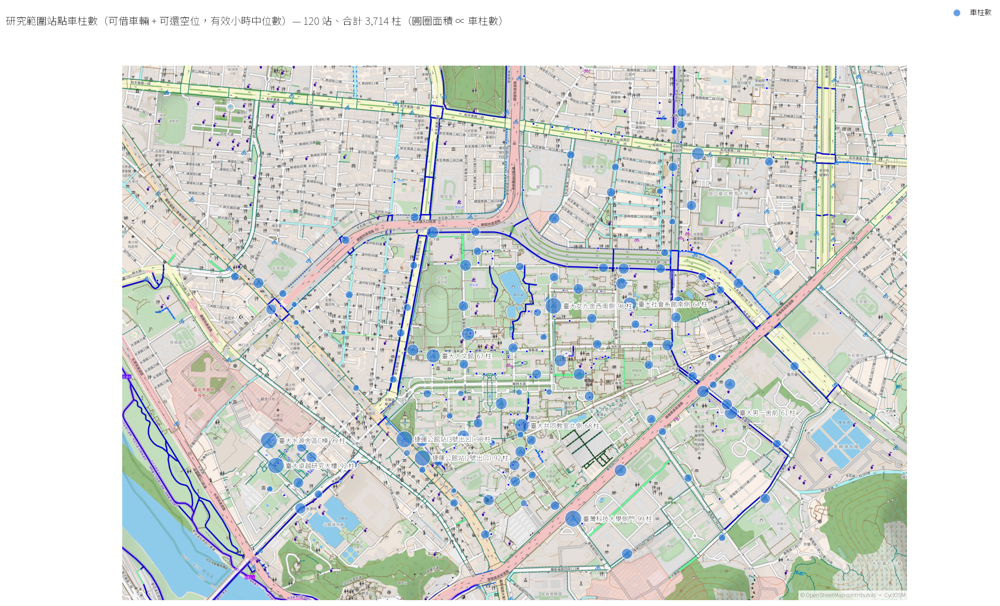

表 7-1　車柱數與周轉率（N = 120 站；周轉率 = 每日平均（借出+還入）÷ 車柱數）


,站名,車柱數,有效小時數,每柱每日周轉
0,捷運公館站(1號出口),12.0,17159,30.03
1,溫州公園,5.0,17173,29.39
2,羅斯福路三段311號前,11.0,17177,28.81
3,銘傳國小側門,7.0,17150,27.41
4,捷運科技大樓站,28.0,17162,27.37
5,和平復興路口西北側,9.0,17153,26.19
6,捷運公館站(4號出口),12.0,17165,24.21
7,辛亥復興路口西北側,16.0,17154,20.70
8,和平公園東側,11.0,17154,19.95
9,新生南路三段94巷口,15.0,17151,19.00


In [22]:
# 7b. Dock capacity map -- the real capacity that section 1 could not show
cap = (fv.groupby("station_id")
       .agg(capacity=("docks", "median"), valid_hours=("docks", "size"),
            rides_per_hour=("rider_rent", "mean"), returns_per_hour=("rider_return", "mean")))
cap["turnover"] = 24 * (cap["rides_per_hour"] + cap["returns_per_hour"]) / cap["capacity"]  # daily (rent+return) per dock
cap_df = STATIONS.join(cap, how="inner")
cmax = cap_df["capacity"].max()

img = draw_circles(cap_df, "capacity", cmax, lambda r: BLUE)
fig, (ax,) = map_figure(1)
show_map(ax, img, cap_df, "capacity", n_labels=10, fmt="{:.0f} 柱")
add_header(fig, f"研究範圍站點車柱數（可借車輛 + 可還空位，有效小時中位數）— {len(cap_df)} 站、合計 {cap_df['capacity'].sum():,.0f} 柱"
                "（圓圈面積 ∝ 車柱數）", [dot(BLUE, "車柱數", .7)])
plt.show()

print(f"表 7-1　車柱數與周轉率（N = {len(cap_df)} 站；周轉率 = 每日平均（借出+還入）÷ 車柱數）")
display(cap_df[["name", "capacity", "valid_hours", "turnover"]]
        .rename(columns={"name": "站名", "capacity": "車柱數", "valid_hours": "有效小時數", "turnover": "每柱每日周轉"})
        .sort_values("每柱每日周轉", ascending=False).round(2).reset_index(drop=True).head(15))

findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


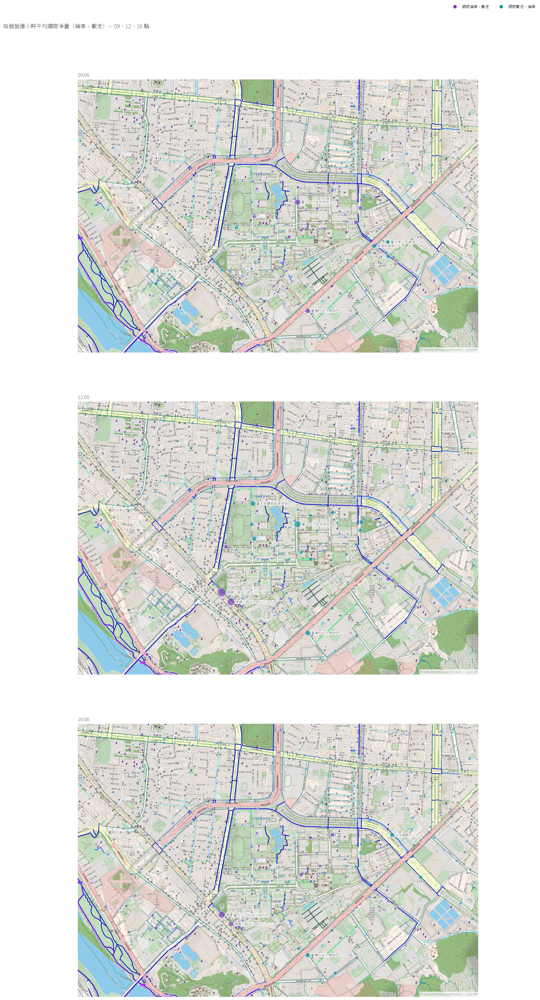

表 7-2　調度淨量 vs. 騎乘淨流量（每個營運小時平均；調度淨量 > 0 代表補車）


,09點_調度淨量,12點_調度淨量,16點_調度淨量,09點_騎乘淨流量,12點_騎乘淨流量,16點_騎乘淨流量
name,,,,,,
臺大女九舍西南側,3.00,-4.19,0.37,6.48,-3.89,-2.48
臺灣科技大學側門,2.11,-2.63,-1.93,2.69,-3.74,-12.42
臺大水源舍區C棟,-1.91,0.05,0.40,-5.14,-0.81,1.59
基隆長興路口,-1.77,-0.46,0.12,-7.88,-1.11,-0.88
臺大男八舍東側,-1.40,-0.07,-0.03,-4.87,0.40,0.08
臺大卓越研究大樓,-1.35,0.09,0.80,-5.40,-1.57,0.06
臺大男一舍前,-1.26,1.58,0.37,-8.99,-0.59,2.28
臺大鄭江樓北側,1.23,-0.61,-0.64,2.30,-2.27,-3.62
臺大社會系館南側,1.14,-1.07,0.04,0.71,-2.78,-2.19


各時刻站點間「調度淨量」與「騎乘淨流量」的相關係數（負值 = 調度在抵銷騎乘造成的不平衡）： 09 點 +0.79、12 點 +0.81、16 點 +0.81


In [23]:
# 7c. Station-hour averages at 09 / 12 / 16 and a shared map helper for section 7
FLOW_HOURS = HOURS  # [9, 12, 16], same as sections 4-5
PURPLE, TEAL = "#7b3fbf", "#159a9c"

sh = (fv.groupby(["station_id", "hour"])
      .agg(rider_rent=("rider_rent", "mean"), rider_return=("rider_return", "mean"),
           dispatch_in=("dispatch_in", "mean"), dispatch_out=("dispatch_out", "mean"),
           empty_share=("empty_end", "mean"), full_share=("full_end", "mean"), n_hours=("rider_rent", "size")))
sh["rider_net"] = sh["rider_return"] - sh["rider_rent"]
sh["dispatch_net"] = sh["dispatch_in"] - sh["dispatch_out"]
sh["dispatch_total"] = sh["dispatch_in"] + sh["dispatch_out"]
sh["unusable_share"] = sh["empty_share"] + sh["full_share"]
sh = sh.reset_index().merge(STATIONS.reset_index(), on="station_id")
sh_sel = sh[sh["hour"].isin(FLOW_HOURS)].reset_index(drop=True)


def flow_maps(df, value_col, color_fn, suptitle, legend, label_fn, n_labels=5, alpha=0.65):
    """Three stacked map panels (one per FLOW_HOURS) on one shared circle scale, labelled by label_fn(row)."""
    vmax = df[value_col].abs().max()
    fig, axes = map_figure(len(FLOW_HOURS))
    for ax, h in zip(axes, FLOW_HOURS):
        d = df[df["hour"] == h].reset_index(drop=True)
        ax.imshow(draw_circles(d, value_col, vmax, color_fn, alpha=alpha))
        ax.set_axis_off()
        ax.set_title(f"{h:02d}:00", loc="left", fontsize=11, color=INK, pad=6)
        for _, r in d.reindex(d[value_col].abs().sort_values(ascending=False).index).head(n_labels).iterrows():
            x, y = to_px(r["longitude"], r["latitude"])
            ax.annotate(label_fn(r), (x + radius(r[value_col], vmax) + 4, y), va="center", fontsize=8, color=INK,
                        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
        attribution(ax)
    add_header(fig, suptitle, legend)
    plt.show()


# Rebalancing map: net bikes moved by trucks (purple = trucks drop bikes off, teal = trucks take bikes away)
flow_maps(sh_sel, "dispatch_net", lambda r: PURPLE if r["dispatch_net"] > 0 else TEAL,
          "每個營運小時平均調度淨量（補車 − 載走）— 09、12、16 點",
          [dot(PURPLE, "調度補車 > 載走"), dot(TEAL, "調度載走 > 補車")],
          lambda r: f"{r['name']}  {r['dispatch_net']:+.1f}")

print("表 7-2　調度淨量 vs. 騎乘淨流量（每個營運小時平均；調度淨量 > 0 代表補車）")
tbl = sh_sel.pivot_table(index="name", columns="hour", values=["dispatch_net", "rider_net"]).round(2)
tbl.columns = [f"{h:02d}點_{'調度淨量' if c == 'dispatch_net' else '騎乘淨流量'}" for c, h in tbl.columns]
display(tbl.sort_values(f"{FLOW_HOURS[0]:02d}點_調度淨量", key=abs, ascending=False).head(15))
corr = {h: g["dispatch_net"].corr(g["rider_net"]) for h, g in sh_sel.groupby("hour")}
print("各時刻站點間「調度淨量」與「騎乘淨流量」的相關係數（負值 = 調度在抵銷騎乘造成的不平衡）：",
      "、".join(f"{h:02d} 點 {c:+.2f}" for h, c in corr.items()))

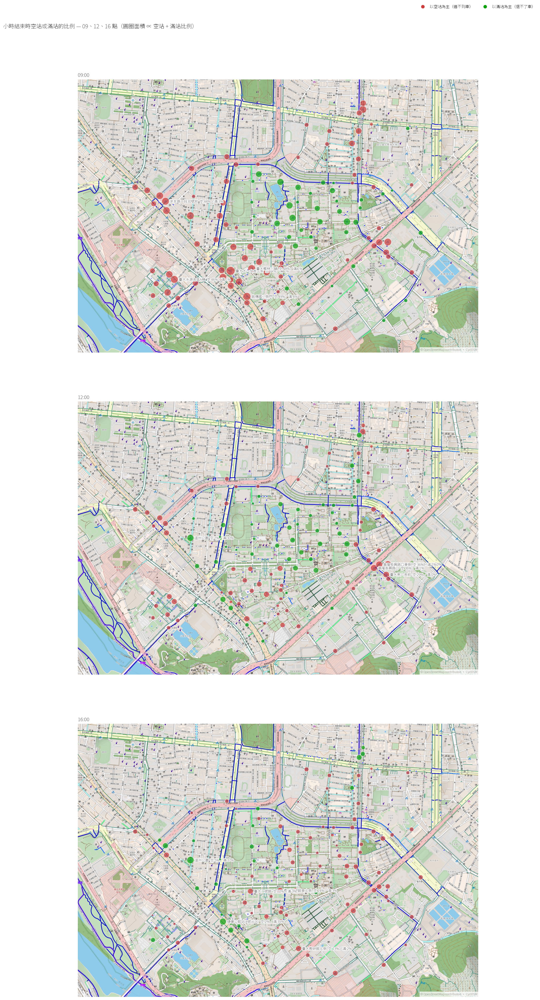

表 7-3　空站／滿站比例（N = 每站每時刻的有效小時數；依 09 點空站+滿站比例排序）


,09點_空站,12點_空站,16點_空站,09點_滿站,12點_滿站,16點_滿站
name,,,,,,
臺大大一女舍北側,63.55%,17.32%,2.65%,0.70%,0.56%,3.21%
銘傳國小側門,49.23%,16.08%,5.17%,3.92%,10.77%,18.72%
臺大椰林小舖,48.18%,15.20%,3.63%,0.56%,0.56%,1.39%
臺大水源舍區A棟,46.37%,24.02%,2.37%,0.70%,0.56%,1.39%
辛亥路一段30號前,43.72%,14.41%,7.67%,2.93%,9.93%,17.29%
復興南路二段273號前,42.80%,24.76%,4.89%,2.80%,3.64%,11.45%
臺大男八舍東側,44.69%,36.03%,18.13%,0.56%,0.42%,0.42%
捷運臺電大樓站(2號出口),43.64%,23.08%,3.91%,0.84%,2.66%,5.73%
羅斯福路三段245號前,39.16%,12.87%,12.69%,5.31%,11.47%,11.02%


In [24]:
# 7d. Empty / full risk map: share of operating hours that END with 0 bikes (empty) or 0 free docks (full)
flow_maps(sh_sel, "unusable_share", lambda r: RED if r["empty_share"] >= r["full_share"] else GREEN,
          "小時結束時空站或滿站的比例 — 09、12、16 點（圓圈面積 ∝ 空站 + 滿站比例）",
          [dot(RED, "以空站為主（借不到車）"), dot(GREEN, "以滿站為主（還不了車）")],
          lambda r: f"{r['name']}  空 {r['empty_share']:.0%}／滿 {r['full_share']:.0%}", alpha=0.7)

print(f"表 7-3　空站／滿站比例（N = 每站每時刻的有效小時數；依 {FLOW_HOURS[0]:02d} 點空站+滿站比例排序）")
risk = sh_sel.pivot_table(index="name", columns="hour", values=["empty_share", "full_share"])
risk.columns = [f"{h:02d}點_{'空站' if c == 'empty_share' else '滿站'}" for c, h in risk.columns]
order = (risk[f"{FLOW_HOURS[0]:02d}點_空站"] + risk[f"{FLOW_HOURS[0]:02d}點_滿站"]).sort_values(ascending=False).index
display(risk.loc[order].head(15).map(pct))

findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


findfont: Failed to find font weight normal for Noto Sans TC, now using 100.


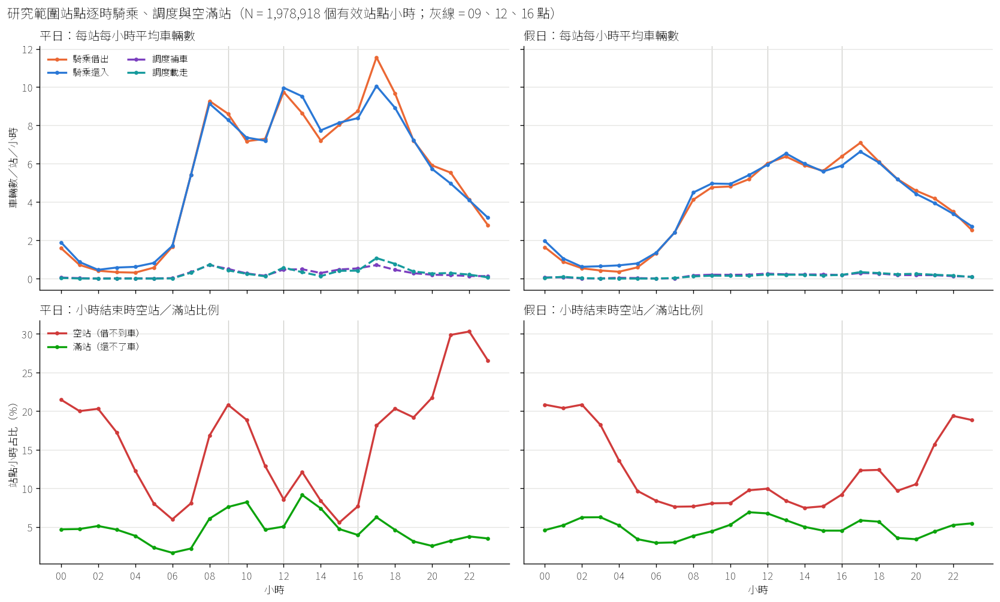

表 7-4　逐時平均（每站每小時；空站／滿站為占比）


,平日_騎乘借出,平日_騎乘還入,平日_調度補車,平日_調度載走,平日_空站比例,平日_滿站比例,假日_騎乘借出,假日_騎乘還入,假日_調度補車,假日_調度載走,假日_空站比例,假日_滿站比例
hour,,,,,,,,,,,,
0,1.594,1.898,0.059,0.034,0.215,0.047,1.642,1.968,0.064,0.043,0.208,0.046
1,0.716,0.867,0.026,0.010,0.200,0.047,0.882,1.054,0.071,0.095,0.204,0.052
2,0.412,0.461,0.006,0.004,0.203,0.051,0.541,0.619,0.009,0.031,0.208,0.063
3,0.337,0.581,0.018,0.003,0.173,0.047,0.426,0.648,0.014,0.007,0.182,0.063
4,0.315,0.617,0.016,0.005,0.123,0.039,0.362,0.694,0.047,0.003,0.136,0.052
5,0.575,0.820,0.014,0.004,0.080,0.023,0.591,0.796,0.029,0.004,0.097,0.034
6,1.671,1.712,0.028,0.011,0.060,0.017,1.329,1.358,0.010,0.004,0.084,0.030
7,5.413,5.403,0.342,0.309,0.081,0.022,2.421,2.412,0.017,0.035,0.076,0.030
8,9.280,9.136,0.710,0.737,0.168,0.061,4.121,4.497,0.171,0.116,0.077,0.039


In [25]:
# 7e. Hourly profile across all mapped stations: rider vs. truck flows, and empty/full share (weekday vs. holiday)
prof = (fv.groupby(["day_type", "hour"], observed=True)
        .agg(rider_rent=("rider_rent", "mean"), rider_return=("rider_return", "mean"),
             dispatch_in=("dispatch_in", "mean"), dispatch_out=("dispatch_out", "mean"),
             empty_share=("empty_end", "mean"), full_share=("full_end", "mean"), n=("rider_rent", "size"))
        .reset_index())

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True, sharey="row")
series_top = [("rider_rent", "騎乘借出", ORANGE, "-"), ("rider_return", "騎乘還入", BLUE, "-"),
              ("dispatch_in", "調度補車", PURPLE, "--"), ("dispatch_out", "調度載走", TEAL, "--")]
series_bot = [("empty_share", "空站（借不到車）", RED), ("full_share", "滿站（還不了車）", GREEN)]
for j, label in enumerate(["平日", "假日"]):
    p = prof[prof["day_type"] == label]
    ax = axes[0, j]
    for col, name, color, ls in series_top:
        ax.plot(p["hour"], p[col], ls, color=color, lw=2, marker="o", ms=3, label=name)
    ax.set_title(f"{label}：每站每小時平均車輛數", loc="left", fontsize=12, color=INK)
    ax = axes[1, j]
    for col, name, color in series_bot:
        ax.plot(p["hour"], 100 * p[col], color=color, lw=2, marker="o", ms=3, label=name)
    ax.set_title(f"{label}：小時結束時空站／滿站比例", loc="left", fontsize=12, color=INK)
    ax.set_xticks(range(0, 24, 2), [f"{h:02d}" for h in range(0, 24, 2)])
    ax.set_xlabel("小時")
for ax in axes.flat:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
    ax.set_axisbelow(True)
    for h in FLOW_HOURS:
        ax.axvline(h, color="#cfcfca", lw=0.8, zorder=0)
axes[0, 0].set_ylabel("車輛數／站／小時")
axes[1, 0].set_ylabel("站點小時占比（%）")
axes[0, 0].legend(frameon=False, ncol=2, fontsize=9)
axes[1, 0].legend(frameon=False, fontsize=9)
fig.suptitle(f"研究範圍站點逐時騎乘、調度與空滿站（N = {len(fv):,} 個有效站點小時；灰線 = 09、12、16 點）",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.show()

print("表 7-4　逐時平均（每站每小時；空站／滿站為占比）")
PROF_LABELS = {"rider_rent": "騎乘借出", "rider_return": "騎乘還入", "dispatch_in": "調度補車",
               "dispatch_out": "調度載走", "empty_share": "空站比例", "full_share": "滿站比例"}
show_prof = prof.pivot_table(index="hour", columns="day_type", observed=True, values=list(PROF_LABELS))
show_prof = show_prof[[(c, d) for d in ["平日", "假日"] for c in PROF_LABELS]]
show_prof.columns = [f"{d}_{PROF_LABELS[c]}" for c, d in show_prof.columns]
display(show_prof.round(3))

In [ ]:
# 7f. Cross-check: rentals counted by the flow panel vs. OD trip records, same station-hours only
od_rent = (trips.loc[rent_in].groupby(["rent_station_id", "rent_time"], observed=True).size()
           .rename("od_rent").rename_axis(["station_id", "datetime"]))
od_ret = (trips.loc[return_in].groupby(["return_station_id", "return_time"], observed=True).size()
          .rename("od_return").rename_axis(["station_id", "datetime"]))
xc = (fv.set_index(["station_id", "datetime"])[["rider_rent", "rider_return"]]
      .join(od_rent).join(od_ret).fillna({"od_rent": 0, "od_return": 0}).astype("int64"))
xs = xc.groupby(level="station_id").sum().join(STATIONS["name"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, (fcol, ocol, name, color) in zip(axes, [("rider_rent", "od_rent", "借出", ORANGE),
                                                ("rider_return", "od_return", "還入", BLUE)]):
    ax.scatter(xs[ocol], xs[fcol], s=28, color=color, edgecolor="white", linewidth=0.8, alpha=0.85)
    lim = 1.05 * max(xs[ocol].max(), xs[fcol].max())
    ax.plot([0, lim], [0, lim], color=INK2, lw=1, ls="--", label="y = x（兩份資料一致）")
    ratio = xs[fcol].sum() / xs[ocol].sum()
    r = xs[fcol].corr(xs[ocol])
    for _, row in xs.assign(gap=(xs[fcol] - xs[ocol]).abs()).nlargest(4, "gap").iterrows():
        ax.annotate(row["name"], (row[ocol], row[fcol]), xytext=(4, 4), textcoords="offset points", fontsize=8,
                    color=INK, path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel(f"OD 旅次資料：{name}筆數")
    ax.set_ylabel(f"flow 資料：rider_{'rent' if name == '借出' else 'return'}")
    ax.set_title(f"{name}：相關係數 {r:.3f}，flow ÷ OD = {ratio:.3f}", loc="left", fontsize=12, color=INK)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle(f"站點層級交叉核對：flow 面板 vs. OD 旅次（同一批有效站點小時，N = {len(xs)} 站）",
             x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.show()

print("表 7-5　兩份資料差異最大的站點（借出）")
display(xs.assign(差異=xs["rider_rent"] - xs["od_rent"], 比值=(xs["rider_rent"] / xs["od_rent"]).round(3))
        .reindex((xs["rider_rent"] - xs["od_rent"]).abs().sort_values(ascending=False).index)
        [["name", "rider_rent", "od_rent", "差異", "比值"]].head(10))

## 總結
（將於執行後依實際輸出回填，對應 Background 的 Main Findings and Takeaways）
